# 👗 Smart Fashion AI with Neural Networks (Mid Term)

**Total Marks: 100 (Theory: 10 | Practical: 90)**  


---

**Instructions:**
1. Enter your course email in the cell below.
2. Read the story and problem descriptions carefully.
3. Complete the code in cells containing `# YOUR CODE HERE`. Do not modify the test cells.
4. Run all cells sequentially to ensure your tests pass before submitting.
5. Have fun!

In [43]:
# Enter your course email here
student_email = "md.faisalmia994@gmail.com" # Example: "your.name@university.edu"
print(f"Email : {student_email}")

Email : md.faisalmia994@gmail.com


---

## 📖 Story: StyleAI — Smart Fashion Recognition

You've just joined **StyleAI**, a startup building an AI-powered wardrobe assistant app. The app lets users snap a photo of any clothing item and instantly classifies it. Your job is to build the **image classification model** that powers this feature.

The dataset is **Fashion-MNIST** — 28×28 grayscale images of 10 clothing categories:

| Label | Class Name |
|-------|------------|
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |


---

## Question 1: Theory (10 Marks)

### Part A (3 Marks)
Explain the difference between **Sigmoid** and **ReLU** activation functions. Why is ReLU preferred in hidden layers of deep networks? What problem does Sigmoid cause during backpropagation in deep networks?

### Part B (4 Marks)
In the context of **Gradient Descent**:
- What is the difference between **Batch Gradient Descent**, **Stochastic Gradient Descent (SGD)**, and **Mini-batch Gradient Descent**?
- State one advantage and one disadvantage of each.
- Which type would you recommend for training on Fashion-MNIST (60,000 images), and why?

### Part C (3 Marks)
In our Fashion-MNIST problem (10 classes):
1. Why do we use `nn.CrossEntropyLoss` instead of `nn.BCELoss`?
2. Why should we **NOT** put `nn.Softmax` as the last layer when using `nn.CrossEntropyLoss`?
3. What does `loss.backward()` do?

*Double-click here to write your answers*

**Part A Answer:**
Sigmoid is used for binary classification but ReLu is used for multi-class classification. Also ReLu is used in hidden layers. Output of sigmoid is (0,1) but ReLu is (0 to infinity). Computational cost of sigmoid is high while for ReLu is low.



**Part B Answer:**

In Batch Gradient Descent, entire data set is used in each epoch. Stochastic uses one sample per once sample. Mini batch uses a small number of batch in each batch.

## Batch Gradient Descent:
### Advantage:
Provides a smooth and direct global minimum path convergence.
### Disadvantage:
It loads entire dataset and thus it become offen impossible to work with.

## Stochastic Gradient Descent:
### Advantage:
Requires minimal memory and escapes the local minima due to high variance in gradient descent.
### Disadvantage:
The high variance causes loss function to fluctuate, causing covergence unstable.

## Mini-batch Gradient
### Advantage:
It provides stability to reach to global minima while shortening computational time and saving memory.
### Disadvantage:
Introduces extra hyperpameters(like - learning rate and batch-size)

## Fashion MNIST:
Mini-batch Gradient Descent (with a typical batch size of 2,4,8,16,32,64, or 128) is the ideal choice for Fashion-MNIST.

Batch Gradient Descent takes high memory and makes the process slower. Stochastic is noisy and inefficient. Mini-batch gradient descent utilizes hardware parallelization effectively, keeps memory usage low, and provides a stable enough gradient descent trajectory to train an accurate neural network efficiently.

**Part C Answer:**

## 1st answer:
nn.CrossEntropyLoss is a base class. It contains -

i) Model parameter track,

ii) Gradient Computation support.

iii) To send model to GPU.

iv) Model save and load.

Here, BCELoss is calculated after applying ReLu activation function. That's why nn.BECLoss isn't calculated manually.

## 2nd answer:
nn.CrossEntropyLoss also performs the inner functionalities of softmax for multi-class output same as it did for BCELoss. That's why we don't need to apply it in the last phase manually.

## 3rd answer:
loss.backward() starts tracking backward Gradient Descent.


---

## Question 2: Load & Explore the Data (15 Marks)

### 2.1 Download the Dataset (1 Marks)

We will use `torchvision.datasets.FashionMNIST` to download the dataset. This is similar to how we loaded data from `.npy` files in class, but here PyTorch handles the download for us.

Run the cell below to download the training and test sets:

In [44]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import numpy as np
import matplotlib.pyplot as plt

# Class names for Fashion-MNIST
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Download Fashion-MNIST — this downloads the data into a ./data folder
# download=True means it will download if not already present
full_train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True)
test_dataset_raw = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True)

train_images_all = full_train_dataset.data.numpy()  # shape: (60000, 28, 28)
train_labels_all = full_train_dataset.targets.numpy()  # shape: (60000,)
test_images_all = test_dataset_raw.data.numpy()
test_labels_all = test_dataset_raw.targets.numpy()

print(f"Training set size: {len(full_train_dataset)}")
print(f"Test set size: {len(test_dataset_raw)}")
print(f"Image shape: {full_train_dataset[0][0].size}")

Training set size: 60000
Test set size: 10000
Image shape: (28, 28)


### 2.2 Visualize Sample Images (5 Marks)

Create a **2×5 subplot figure** (figsize 12×5) showing one sample image from **each of the 10 classes**.
- Display each image in grayscale (`cmap='gray'`)
- Title each subplot with its class name
- Turn off axis ticks

*Hint: loop through classes 0-9, find one sample of each class, and plot it.*

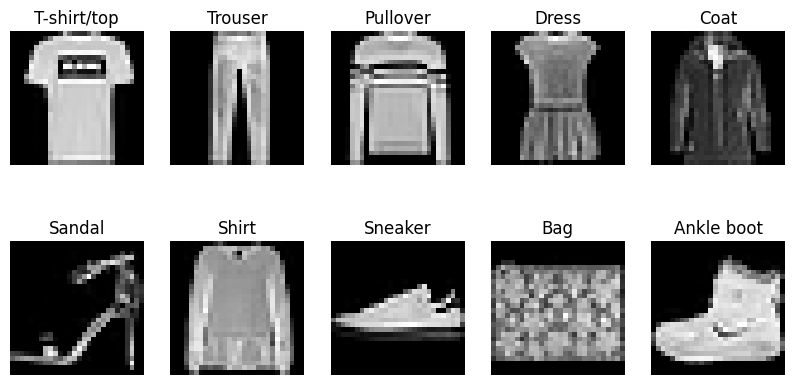

In [45]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
fig,axes = plt.subplots(2,5,figsize=(10,5))
axes = axes.flatten()

for i in range(10):
  idx = np.where(train_labels_all == i)[0][0]
  axes[i].imshow(train_images_all[idx],cmap='gray')
  axes[i].set_title(class_names[i])
  axes[i].axis('off')
plt.show()

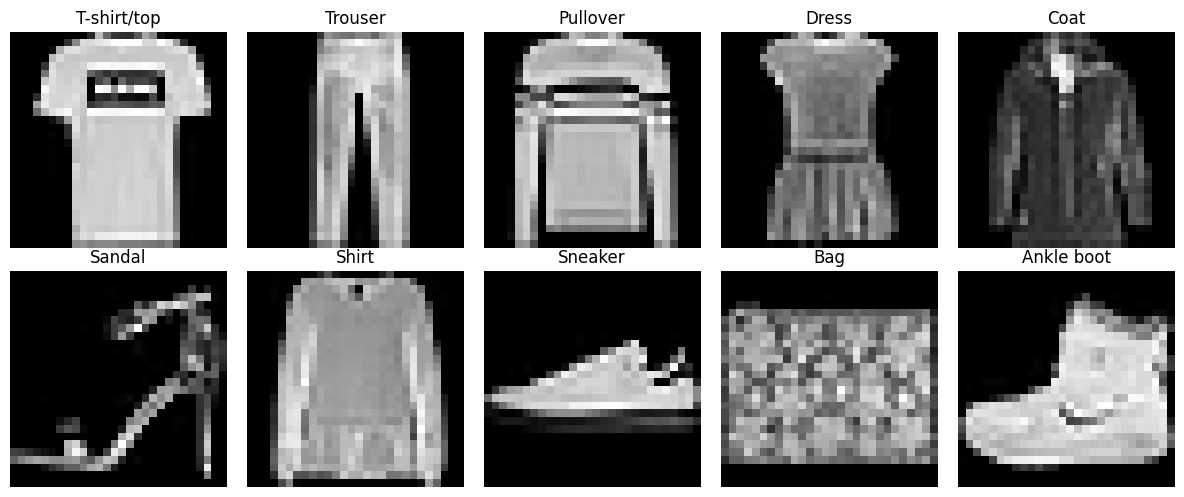

### 2.3 Class Distribution (5 Marks)

Plot a **bar chart** showing how many samples belong to each class in the training set.
- X-axis: class names
- Y-axis: count
- Title: "Training Set Class Distribution"
- Add the count number on top of each bar

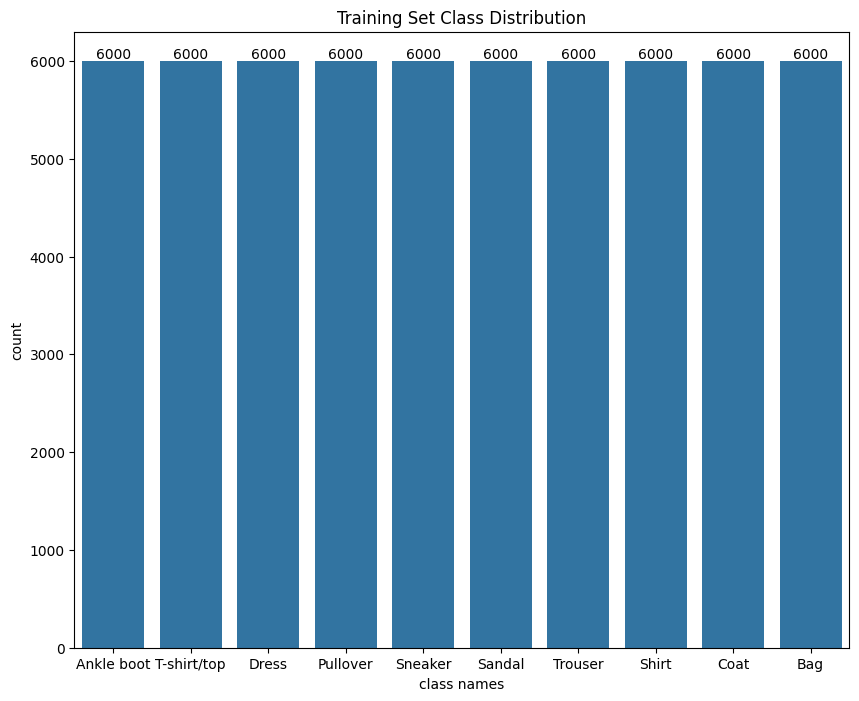

In [46]:
# YOUR CODE HERE
import seaborn as sns
import pandas as pd

class_name = np.array(class_names)[train_labels_all]
df = pd.DataFrame({'class names': class_name})

plt.subplots(figsize=(10,8))
ax = sns.countplot(data=df, x='class names')

ax.bar_label(ax.containers[0])

plt.title('Training Set Class Distribution')
plt.show()

### 2.4 Prepare Tensors and Split (4 Marks)

Now we need to extract the data as NumPy arrays, normalize it, split it, and convert to PyTorch tensors.



**Your tasks:**
1. Normalize pixel values to **[0, 1]** by dividing by 255.0.
2. Split training data into **train (50,000)** and **validation (10,000)** using `train_test_split` with `random_state=42`.
3. Convert all sets to PyTorch tensors — images as `float32`, labels as `long`.

**Required variables:** `X_train, X_val, X_test` (tensors), `y_train, y_val, y_test` (tensors)

In [47]:
from sklearn.model_selection import train_test_split

# YOUR CODE HERE
from sklearn.model_selection import train_test_split

train_images_all = train_images_all.astype('float32') / 255.0
test_images_all = test_images_all.astype('float32')/255.0

X_train_np,X_val_np,y_train_np,y_val_np = train_test_split(train_images_all,train_labels_all,test_size=10000,random_state=42)


X_train = torch.tensor(X_train_np,dtype=torch.float32)
y_train = torch.tensor(y_train_np,dtype=torch.long)

X_val = torch.tensor(X_val_np,dtype=torch.float32)
y_val = torch.tensor(y_val_np,dtype=torch.long)

X_test = torch.tensor(test_images_all,dtype=torch.float32)
y_test = torch.tensor(test_labels_all,dtype=torch.long)

In [48]:
X_train.shape

torch.Size([50000, 28, 28])

In [49]:
# --- TEST CELL (DO NOT MODIFY) ---
assert X_train.shape == (50000, 28, 28), f"Expected X_train shape (50000, 28, 28), got {X_train.shape}"
assert X_val.shape == (10000, 28, 28), f"Expected X_val shape (10000, 28, 28), got {X_val.shape}"
assert X_train.dtype == torch.float32, "X_train should be float32"
assert y_train.dtype == torch.long, "y_train should be long"
assert X_train.max() <= 1.0 and X_train.min() >= 0.0, "Pixel values should be in [0, 1]"
print("✅ Q2.4 Passed!")
print(f"   Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

✅ Q2.4 Passed!
   Train: torch.Size([50000, 28, 28]), Val: torch.Size([10000, 28, 28]), Test: torch.Size([10000, 28, 28])


---

## Question 3: Build DataLoaders (10 Marks)

Create `TensorDataset` and `DataLoader` objects for the train, validation, and test sets.

- **batch_size = 64**
- **shuffle = True** for training, **False** for validation and test

**Required variables:** `train_loader`, `val_loader`, `test_loader`

In [50]:
# YOUR CODE HERE
train_dataset = TensorDataset(X_train,y_train)
val_dataset = TensorDataset(X_val,y_val)
test_dataset = TensorDataset(X_test,y_test)

train_loader = DataLoader(train_dataset,batch_size=64,shuffle=True)
val_loader = DataLoader(val_dataset,batch_size=64,shuffle=False)
test_loader = DataLoader(test_dataset,batch_size=64,shuffle=False)

In [51]:
# --- TEST CELL (DO NOT MODIFY) ---
batch_X, batch_y = next(iter(train_loader))
assert batch_X.shape == (64, 28, 28), f"Batch shape should be (64, 28, 28), got {batch_X.shape}"
assert batch_y.dtype == torch.long, "Labels should be torch.long"
assert batch_X.max() <= 1.0, "Images should be normalized"
print("✅ Q3 Passed!")
print(f"   Batch images shape: {batch_X.shape}")
print(f"   Batch labels shape: {batch_y.shape}")

✅ Q3 Passed!
   Batch images shape: torch.Size([64, 28, 28])
   Batch labels shape: torch.Size([64])


---

## Question 4: Define the Model (15 Marks)

Create a class `FashionClassifier` inheriting from `nn.Module`.

Use `nn.Sequential` with this architecture:

| Layer | Description |
|-------|-------------|
| Flatten | Convert 28×28 → 784 |
| Linear | 784 → 256 |
| ReLU | Activation |
| Linear | 256 → 128 |
| ReLU | Activation |
| Linear | 128 → 64 |
| ReLU | Activation |
| Linear | 64 → 10 |

> **Note**: Do NOT apply Softmax at the output layer.

After defining the class:
1. Create an instance of `FashionClassifier`.
2. Print the model architecture.

In [52]:
# YOUR CODE HERE
class FashionClassifier(nn.Module):
  def __init__(self,input_size,num_classes):
    super().__init__()

    self.network = nn.Sequential(
        nn.Flatten(),
        nn.Linear(input_size,256),
        nn.ReLU(),
        nn.Linear(256,128),
        nn.ReLU(),
        nn.Linear(128,64),
        nn.ReLU(),
        nn.Linear(64,num_classes)
    )

  def forward(self,features):
      output = self.network(features)
      return output

In [53]:
model = FashionClassifier(input_size=28*28,num_classes=10)
print(model)

FashionClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=64, bias=True)
    (6): ReLU()
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [54]:
# --- TEST CELL (DO NOT MODIFY) ---
test_input = torch.randn(5, 28, 28)
test_output = model(test_input)
assert test_output.shape == (5, 10), f"Output shape should be (5, 10), got {test_output.shape}"
total_params = sum(p.numel() for p in model.parameters())
assert total_params > 0, "Model should have trainable parameters"
print("✅ Q4 Passed!")
print(f"   Total parameters: {total_params}")
print(model)

✅ Q4 Passed!
   Total parameters: 242762
FashionClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=64, bias=True)
    (6): ReLU()
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)


---

## Question 5: Train the Model (25 Marks)

### 5.1 Set Up Training (5 Marks)
- Loss function: `nn.CrossEntropyLoss`
- Optimizer: `optim.SGD` with `lr=0.01`
- Number of epochs: **15**

In [55]:
# YOUR CODE HERE

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(),lr=0.01)
epochs = 15

### 5.2 Training Loop (15 Marks)

Write a complete training loop for **15 epochs**.

For each epoch:
- Train on `train_loader` and compute training loss
- Evaluate on `val_loader` (with `torch.no_grad()`) and compute validation loss
- Print: `Epoch {epoch+1}/{epochs} | Train Loss: {:.4f} | Val Loss: {:.4f} `

Store: `train_losses`, `val_losses`, (lists, one value per epoch).

In [56]:
# YOUR CODE HERE

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []


for epoch in range(epochs):

  running_loss = 0.0
  correct = 0
  total = 0

  for images,labels in train_loader:
    optimizer.zero_grad()

    outputs = model(images)
    loss = criterion(outputs,labels)

    loss.backward()

    optimizer.step()

    running_loss+=loss.item()

    _,predicted = torch.max(outputs,1)

    total+=labels.size(0)
    correct+=(predicted==labels).sum().item()

  epoch_train_loss = running_loss/len(train_loader)
  epoch_train_accuracy = 100*(correct/total)

  train_losses.append(epoch_train_loss)
  train_accuracies.append(epoch_train_accuracy)

  val_loss = 0.0
  correct = 0
  total = 0
  with torch.no_grad():
    for images,labels in val_loader:
      outputs = model(images)
      loss = criterion(outputs,labels)
      val_loss+=loss.item()

      _,predicted = torch.max(outputs,1)

    total+=labels.size(0)
    correct+=(predicted==labels).sum().item()

  epoch_val_loss = val_loss/len(val_loader)
  epoch_val_accuracy = 100*(correct/total)

  val_losses.append(epoch_val_loss)
  val_accuracies.append(epoch_val_accuracy)



  print(f'Epoch {epoch+1}/{epochs} | Train loss :{running_loss:.4f} | Validation loss:{val_loss:.4f}')



Epoch 1/15 | Train loss :1484.3992 | Validation loss:188.9886
Epoch 2/15 | Train loss :729.1808 | Validation loss:145.5205
Epoch 3/15 | Train loss :565.8851 | Validation loss:110.4834
Epoch 4/15 | Train loss :496.8899 | Validation loss:101.3242
Epoch 5/15 | Train loss :454.2128 | Validation loss:88.8844
Epoch 6/15 | Train loss :424.4152 | Validation loss:88.6829
Epoch 7/15 | Train loss :401.9084 | Validation loss:80.2744
Epoch 8/15 | Train loss :381.9579 | Validation loss:78.7187
Epoch 9/15 | Train loss :366.7901 | Validation loss:78.3923
Epoch 10/15 | Train loss :354.5012 | Validation loss:72.8991
Epoch 11/15 | Train loss :344.9262 | Validation loss:94.4493
Epoch 12/15 | Train loss :335.4611 | Validation loss:98.2914
Epoch 13/15 | Train loss :326.9737 | Validation loss:67.6396
Epoch 14/15 | Train loss :320.8011 | Validation loss:66.8217
Epoch 15/15 | Train loss :314.7310 | Validation loss:66.5214


In [57]:
# --- TEST CELL (DO NOT MODIFY) ---
assert len(train_losses) == 15, f"Expected 15 epochs, got {len(train_losses)}"
assert len(val_losses) == 15
assert train_losses[-1] < train_losses[0], "Training loss should decrease"
print("✅ Q5.2 Passed!")
print(f"   Final Train Acc: {train_accuracies[-1]:.2f}%, Final Val Acc: {val_accuracies[-1]:.2f}%")

✅ Q5.2 Passed!
   Final Train Acc: 85.93%, Final Val Acc: 93.75%


### 5.3 Test Evaluation (5 Marks)

Evaluate the model on the **test set**. Print the test_accuracy (required_variable)

Also, collect all test predictions and true labels into lists called `all_preds` and `all_labels` (we'll use them for analysis later).

Print: `Test Accuracy: {:.2f}%`

In [58]:
# YOUR CODE HERE

all_preds = []
all_labels = []

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.tolist())
        all_labels.extend(labels.tolist())

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 84.24%


In [59]:
# --- TEST CELL (DO NOT MODIFY) ---
assert test_accuracy > 40.0, f"Test accuracy should be > 40%, got {test_accuracy:.2f}%"
assert len(all_preds) == len(X_test), "Predictions should cover all test samples"
print(f"✅ Q5.3 Passed! Test Accuracy: {test_accuracy:.2f}%")

✅ Q5.3 Passed! Test Accuracy: 84.24%


---

## Question 6: Visualize & Analyze Results (25 Marks)

### 6.1 Plot Training Loss vs Validation Loss (5 Marks)

Plot **Training Loss** and **Validation Loss** on the same figure across epochs.
- Include a legend, title ("Loss Curve"), and axis labels.

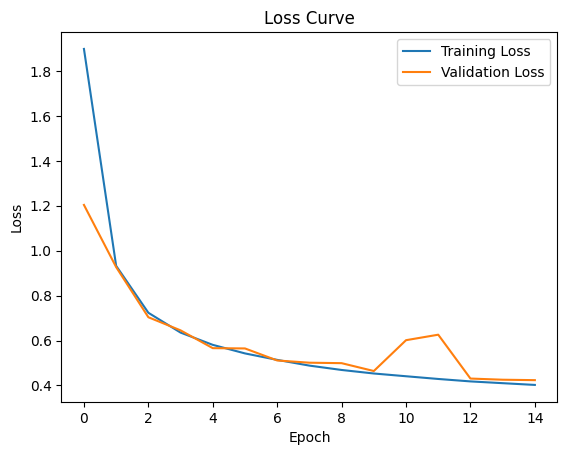

In [60]:
# YOUR CODE HERE

plt.plot(train_losses,label='Training Loss')
plt.plot(val_losses,label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss Curve')
plt.show()

### 6.2 Plot Training Accuracy vs Validation Accuracy (5 Marks)

Plot **Training Accuracy** and **Validation Accuracy** on the same figure across epochs.
- Include a legend, title ("Accuracy Curve"), and axis labels.

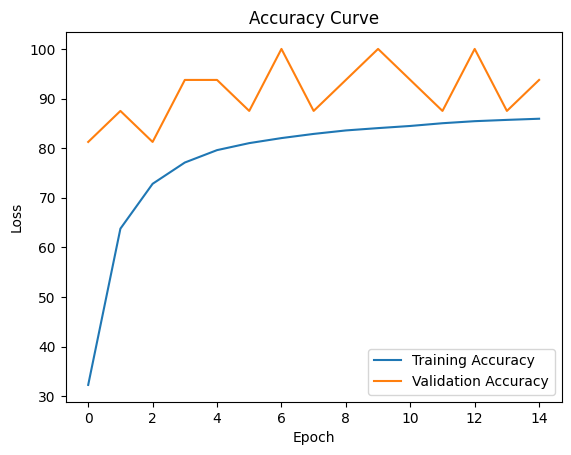

In [61]:
# YOUR CODE # YOUR CODE HERE

plt.plot(train_accuracies,label='Training Accuracy')
plt.plot(val_accuracies,label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Accuracy Curve')
plt.show()


### 6.3 Confusion Matrix (5 Marks)

Using `sklearn.metrics`:
1. Compute the confusion matrix on test predictions.
2. Display it as a heatmap using `ConfusionMatrixDisplay` with `class_names` as labels.
3. Title: "StyleAI Fashion Classifier — Test Confusion Matrix"

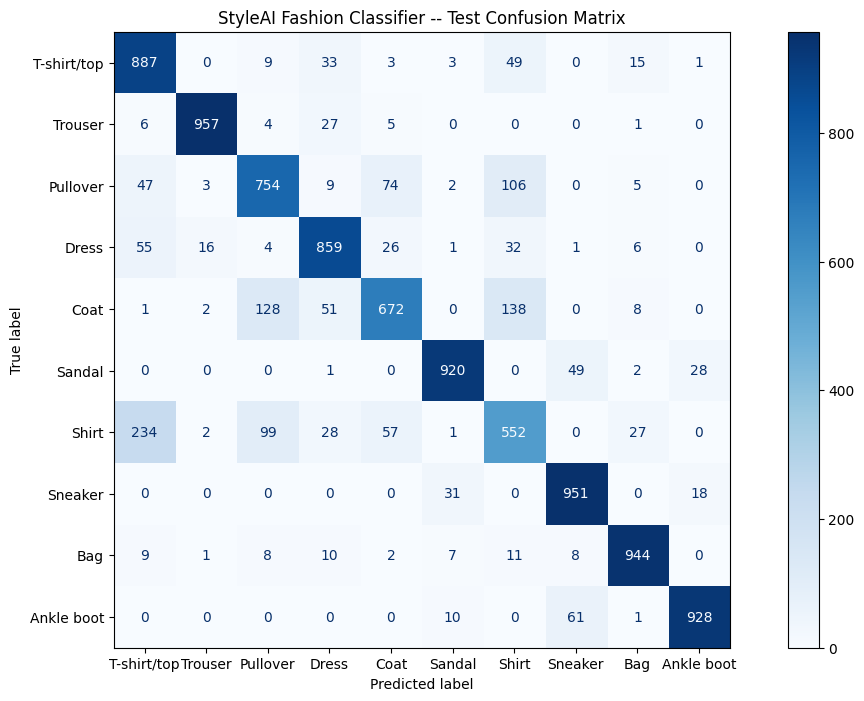

In [62]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# YOUR CODE HERE

cm = confusion_matrix(all_labels,all_preds)

fig,ax = plt.subplots(figsize=(15,8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)
disp.plot(ax=ax,cmap='Blues')
plt.title('StyleAI Fashion Classifier -- Test Confusion Matrix')
plt.show()


### 6.4 Classification Report (5 Marks)

Print the `classification_report` from sklearn using `target_names=class_names`.

In [63]:
from sklearn.metrics import classification_report

# YOUR CODE HERE

cls_report = classification_report(all_labels,all_preds,target_names=class_names)
print(cls_report)

              precision    recall  f1-score   support

 T-shirt/top       0.72      0.89      0.79      1000
     Trouser       0.98      0.96      0.97      1000
    Pullover       0.75      0.75      0.75      1000
       Dress       0.84      0.86      0.85      1000
        Coat       0.80      0.67      0.73      1000
      Sandal       0.94      0.92      0.93      1000
       Shirt       0.62      0.55      0.58      1000
     Sneaker       0.89      0.95      0.92      1000
         Bag       0.94      0.94      0.94      1000
  Ankle boot       0.95      0.93      0.94      1000

    accuracy                           0.84     10000
   macro avg       0.84      0.84      0.84     10000
weighted avg       0.84      0.84      0.84     10000



### 6.5 Written Analysis (5 Marks)

In the markdown cell below, answer:
1. Which two classes are **most often confused** with each other? Look at the confusion matrix and explain **why** (think about visual similarity).
2. Is the model **overfitting or underfitting**? How can you tell from the learning curves?

*Double-click here to write your analysis*

**Your Analysis:**

## 1st answer:
Shirt and Coat are most often confused with each other. They both have quiet similar properties and can be used vice-versa.

## 2nd answer:
The model is overfitting. From the loss function curve it's clearly visible that upto 6 or 7 epochs both decreased similarly but after that validation loss increased compared to training loss. Also in the accuracy curve validation loss kept upper hand compared to training accuracy. So overall, it show's the model to be overfitting.


